# Superstore Sales Data Analysis & Business Insights Dashboard

In this notebook, we will:
1. Extract and preprocess the sales data.
2. Analyze sales trends over time.
3. Identify top-performing products and regions.
4. Create visual summaries for business decision-making.

In [1]:
import zipfile
import os

zip_path = '/content/aswal.zip'
extract_path = '/content/extracted_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted files:")
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

Extracted files:
/content/extracted_data/Sample - Superstore.csv


In [2]:
import pandas as pd
import numpy as np

# Load the dataset with latin1 encoding due to potential special characters
df = pd.read_csv('/content/extracted_data/Sample - Superstore.csv', encoding='latin1')

# Display basic information
print("Dataset Shape:", df.shape)
print("\nDataset Columns & Data Types:")
print(df.info())

# Check for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Parse Order Date and Ship Date as datetime
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

# Create extra time-series columns for trend analysis
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.to_period('M')

print("\nProcessed Data Preview:")
df.head()

Dataset Shape: (9994, 21)

Dataset Columns & Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,2016-11
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,2016-11
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,2016-06
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,2015-10
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,2015-10


Yearly Sales and Profit Trends:
   Year        Sales      Profit
0  2014  484247.4981  49543.9741
1  2015  470532.5090  61618.6037
2  2016  609205.5980  81795.1743
3  2017  733215.2552  93439.2696


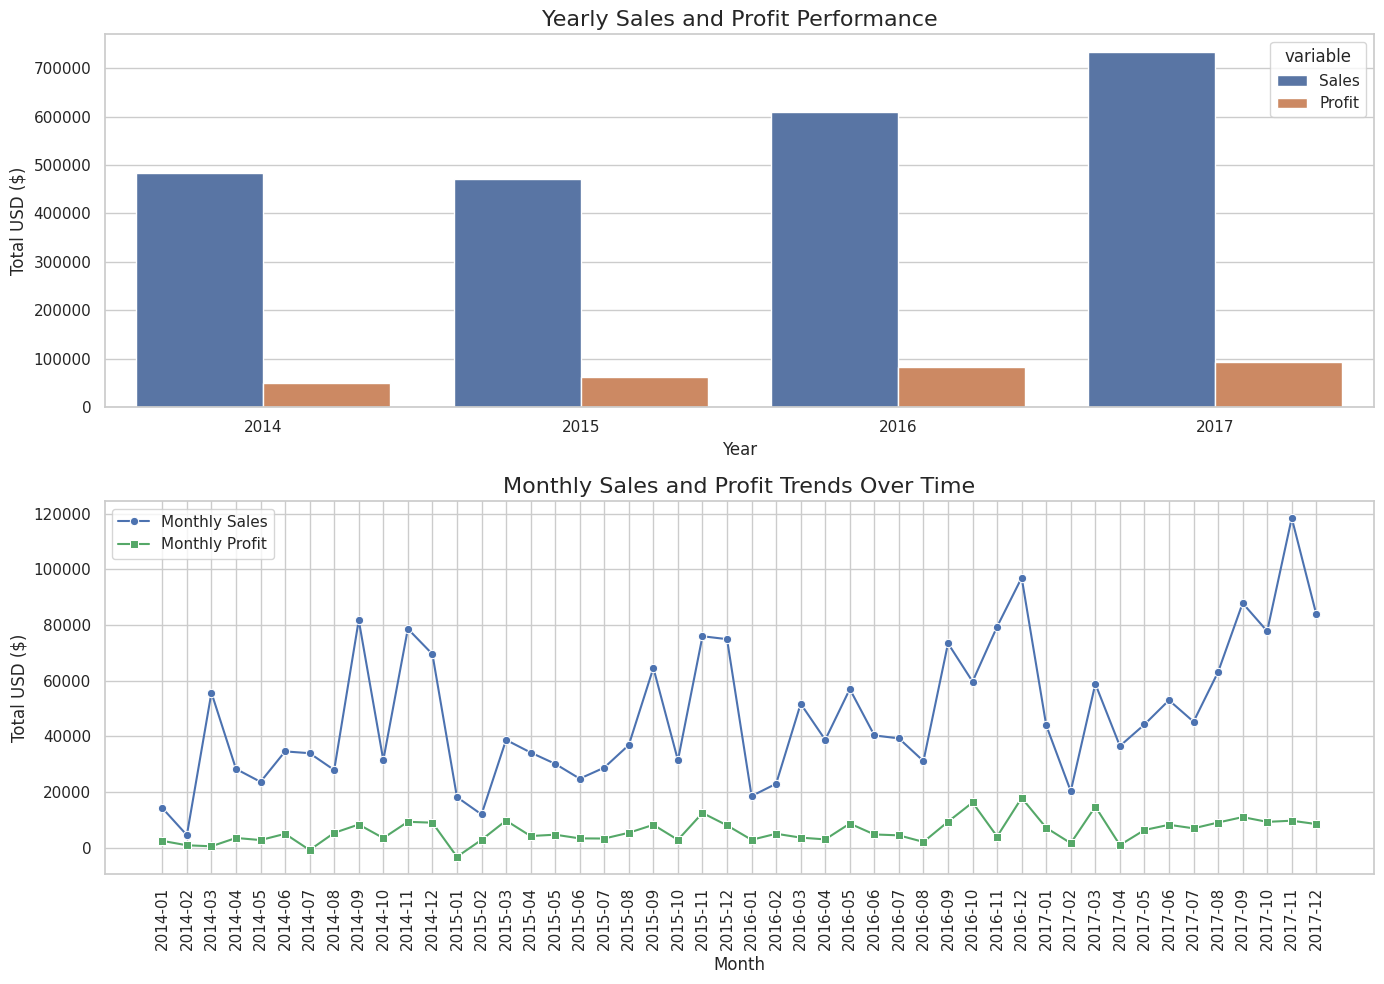

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Yearly Sales and Profit
yearly_perf = df.groupby('Year')[['Sales', 'Profit']].sum().reset_index()
print("Yearly Sales and Profit Trends:")
print(yearly_perf)

# 2. Monthly Sales Trend
monthly_perf = df.groupby('Month')[['Sales', 'Profit']].sum().reset_index()
monthly_perf['Month_str'] = monthly_perf['Month'].astype(str)

# Plotting Trends
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=False)

# Yearly Plot
sns.barplot(ax=axes[0], data=pd.melt(yearly_perf, id_vars=['Year']), x='Year', y='value', hue='variable')
axes[0].set_title('Yearly Sales and Profit Performance', fontsize=16)
axes[0].set_ylabel('Total USD ($)', fontsize=12)
axes[0].set_xlabel('Year', fontsize=12)

# Monthly Plot
sns.lineplot(ax=axes[1], data=monthly_perf, x='Month_str', y='Sales', label='Monthly Sales', marker='o', color='b')
sns.lineplot(ax=axes[1], data=monthly_perf, x='Month_str', y='Profit', label='Monthly Profit', marker='s', color='g')
axes[1].set_title('Monthly Sales and Profit Trends Over Time', fontsize=16)
axes[1].set_ylabel('Total USD ($)', fontsize=12)
axes[1].set_xlabel('Month', fontsize=12)
axes[1].tick_params(axis='x', rotation=90)
axes[1].legend()

plt.tight_layout()
plt.show()

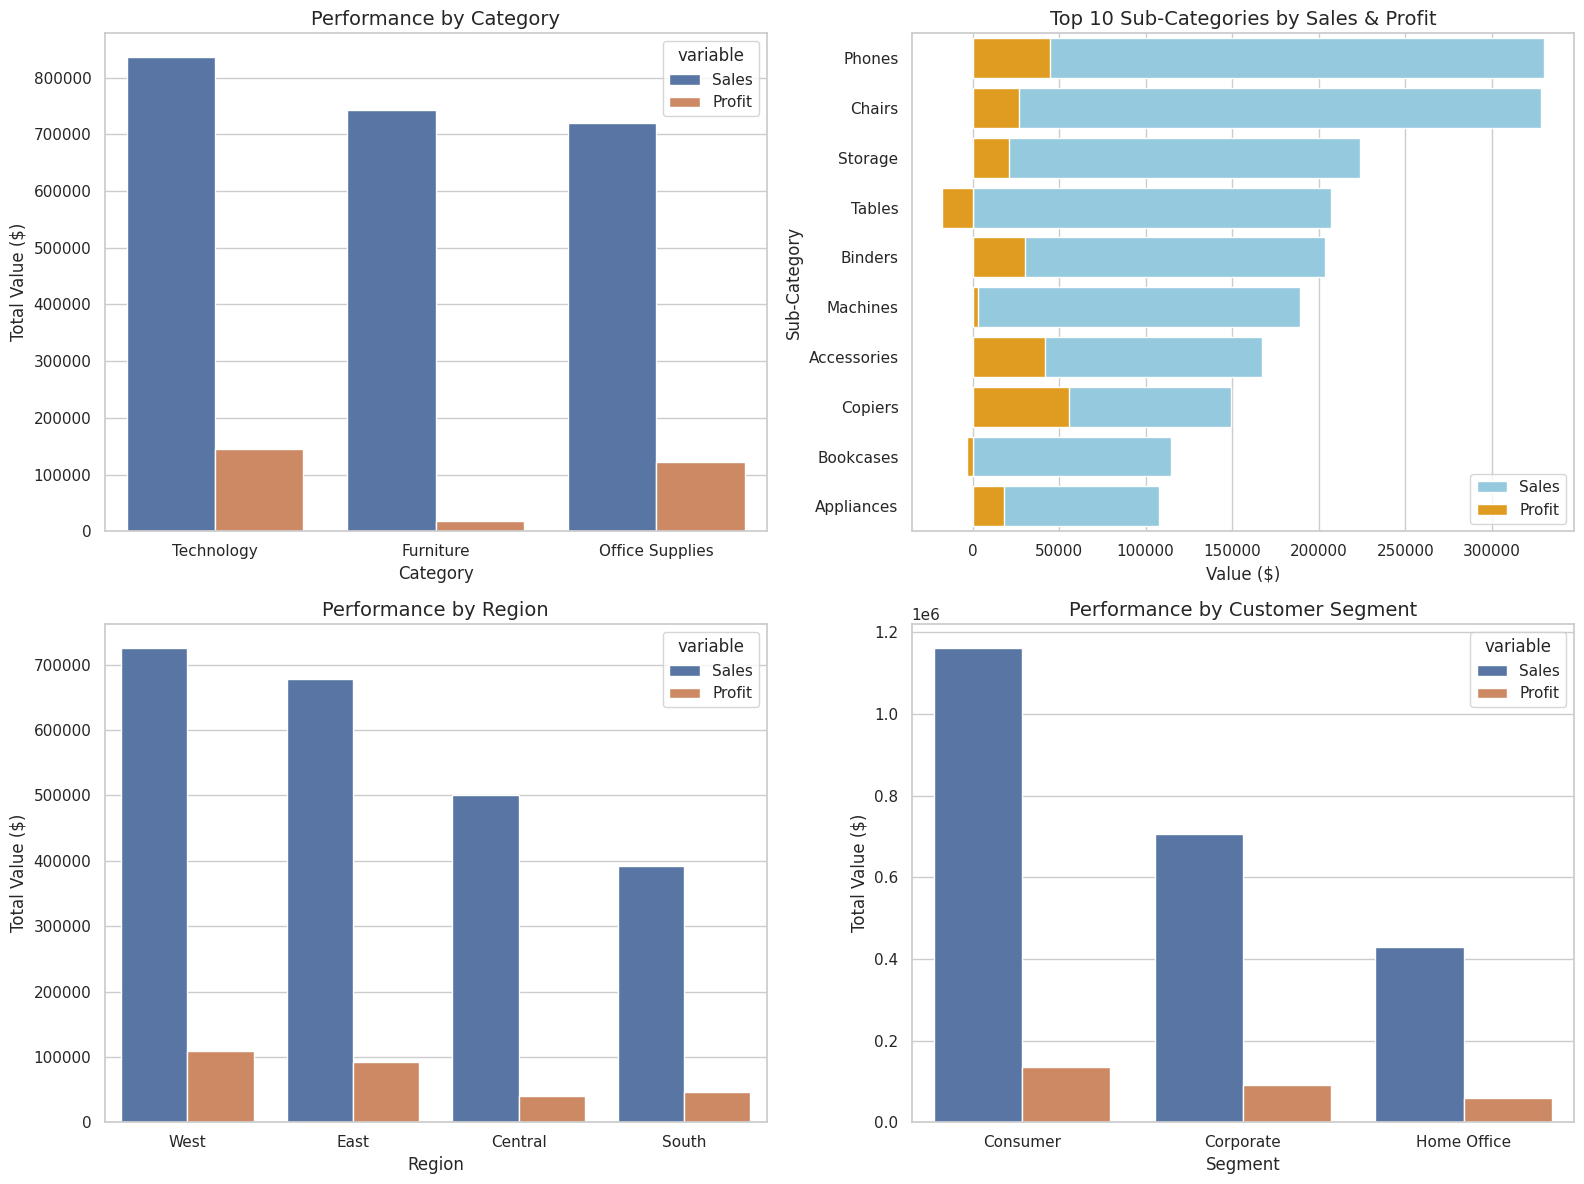

In [4]:
# 1. Category and Sub-category Analysis
cat_perf = df.groupby('Category')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False).reset_index()
subcat_perf = df.groupby('Sub-Category')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False).reset_index().head(10)

# 2. Regional Analysis
region_perf = df.groupby('Region')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False).reset_index()

# 3. Customer Segment Analysis
segment_perf = df.groupby('Segment')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False).reset_index()

# Plotting Top-Performing metrics
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot Category Performance
sns.barplot(ax=axes[0, 0], data=pd.melt(cat_perf, id_vars=['Category']), x='Category', y='value', hue='variable')
axes[0, 0].set_title('Performance by Category', fontsize=14)
axes[0, 0].set_ylabel('Total Value ($)')
axes[0, 0].set_xlabel('Category')

# Plot Top 10 Sub-Categories by Sales
sns.barplot(ax=axes[0, 1], data=subcat_perf, x='Sales', y='Sub-Category', color='skyblue', label='Sales')
sns.barplot(ax=axes[0, 1], data=subcat_perf, x='Profit', y='Sub-Category', color='orange', label='Profit')
axes[0, 1].set_title('Top 10 Sub-Categories by Sales & Profit', fontsize=14)
axes[0, 1].set_xlabel('Value ($)')
axes[0, 1].legend()

# Plot Regional Performance
sns.barplot(ax=axes[1, 0], data=pd.melt(region_perf, id_vars=['Region']), x='Region', y='value', hue='variable')
axes[1, 0].set_title('Performance by Region', fontsize=14)
axes[1, 0].set_ylabel('Total Value ($)')
axes[1, 0].set_xlabel('Region')

# Plot Segment Performance
sns.barplot(ax=axes[1, 1], data=pd.melt(segment_perf, id_vars=['Segment']), x='Segment', y='value', hue='variable')
axes[1, 1].set_title('Performance by Customer Segment', fontsize=14)
axes[1, 1].set_ylabel('Total Value ($)')
axes[1, 1].set_xlabel('Segment')

plt.tight_layout()
plt.show()